In [1]:
# 0.导入相关库
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedShuffleSplit as SS
import tensorflow.python.keras as keras
from matplotlib import pyplot as plt
import os
import tensorflow as tf
import joblib
from sklearn import svm

In [2]:
# 1.数据导入及处理
# 采用GPU训练，没有可以注释掉
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

# 导入数据
raw_data = pd.read_excel("36RNA的原始数据.xlsx").to_numpy()

# 打乱数据
random_index=[i for i in range(2,38)]
np.random.shuffle(random_index)
random_data=raw_data[:,random_index]

# 打乱信息
print('本次打乱矩阵为：{}'.format(random_index))
#print(raw_data[:,random_index[0]])
#print(random_data[:,0])

# 创建输入，使用一维向量
X = random_data.reshape((random_data.shape[0]),36)

# 将label转换为数字，二分类，前三种病为一种，健康为一种
y_dict = {'O':1,'H':1,'L':1,'N':0}
y = np.array([y_dict[i] if i in y_dict else i for i in raw_data[:,1]])
np.unique(y,return_counts=True)


本次打乱矩阵为：[3, 6, 20, 24, 2, 18, 15, 19, 31, 4, 11, 23, 5, 34, 26, 13, 30, 12, 10, 25, 28, 22, 35, 16, 33, 32, 27, 21, 36, 29, 8, 37, 14, 9, 17, 7]


(array([0, 1]), array([1009, 1326], dtype=int64))

In [3]:
# 2.数据分割及模型构建训练
# 分层抽样，保证训练测试集数据比例与整体一致，X_train,y_train为训练集，X_test,y_test为测试集
split = SS(n_splits=1,train_size=0.8)
for train_index, test_index in split.split(X, y):
        print("TRAIN:", len(train_index), "TEST:", len(test_index))
        X_train, X_test = X[train_index], X[test_index]
        y_train, y_test = y[train_index], y[test_index]

# 构建SVM模型
from sklearn import svm
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
# model = svm.SVC(kernel='linear',probability=True,decision_function_shape='ovr')
model = svm.LinearSVC(fit_intercept=False,max_iter=10000)
model.fit(X_train,y_train)

TRAIN: 1868 TEST: 467


C:\Users\chem-DNA259\anaconda\envs\Env\lib\site-packages\sklearn\svm\_base.py:1208: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  ConvergenceWarning,


LinearSVC(fit_intercept=False, max_iter=10000)

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       202
           1       1.00      0.99      0.99       265

    accuracy                           0.99       467
   macro avg       0.99      0.99      0.99       467
weighted avg       0.99      0.99      0.99       467

[[201   1]
 [  3 262]]


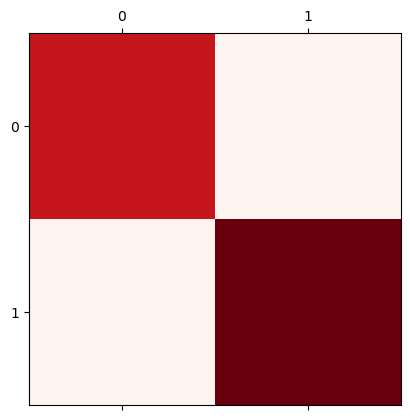

<Figure size 640x480 with 0 Axes>

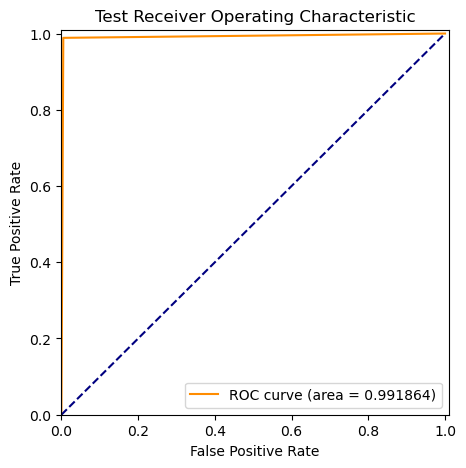

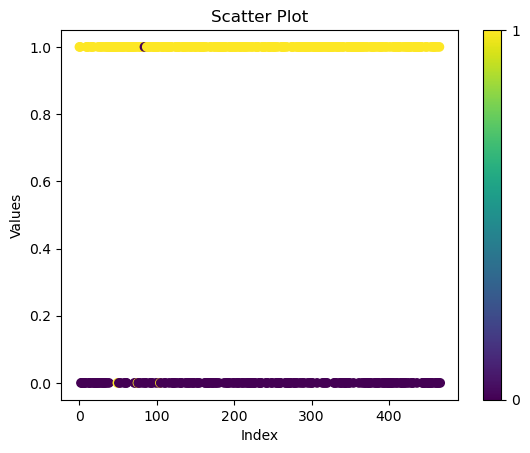

[[-1.53143258 -0.01922888 -0.00507713  0.046523   -0.47140835 -0.0379293
   1.02961893 -0.20449949 -0.39611279 -0.06543756 -0.11505294  0.25688412
  -0.57710847  0.81796442  0.18832355  0.4785436  -0.17272377 -1.15247954
   0.43454976 -0.01202292 -0.4219421   0.62471337  1.16640785 -0.13486293
   0.18612082  0.39479219  0.10780651 -0.65321512  0.93493391 -0.07393952
   0.4960321  -1.01292714 -0.01677418 -0.3873298  -0.10410141 -0.09386249]]
0.0


In [4]:
# 3.分析模型结果
# 绘制混淆矩阵
y_pred = model.predict(X_test)
print(classification_report(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))
plt.matshow(confusion_matrix(y_test,y_pred),cmap=plt.cm.Reds)

# 绘制ROC曲线，y_pred_prob为y_pred对每个分类对应的概率
from sklearn.metrics import roc_curve, auc
# y_pred_prob = list(i[-1] for i in model.predict_proba(X_test))
fpr,tpr,threshold = roc_curve(y_test, y_pred)
roc_auc = auc(fpr,tpr) ###计算auc的值
plt.figure()
plt.figure(figsize=(5,5))
plt.plot(fpr, tpr, color='darkorange', label='ROC curve (area = %0.6f)' % roc_auc) ###假正率为横坐标，真正率为纵坐标做曲线
plt.plot([0, 1], [0, 1], color='navy',  linestyle='--')
plt.xlim([0.0, 1.01])
plt.ylim([0.0, 1.01])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Test Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

# 绘制数据分布图
#list1, list2 = zip(*sorted(zip(y_test, y_pred_prob)))
list1, list2 = y_test, y_pred
plt.scatter(range(len(list2)), list2, c=list1)
plt.title("Scatter Plot")
plt.xlabel("Index")
plt.ylabel("Values")
cbar = plt.colorbar()
cbar.set_ticks([0, 1])
plt.show()

# 输出模型参数
print(model.coef_)
print(model.intercept_)

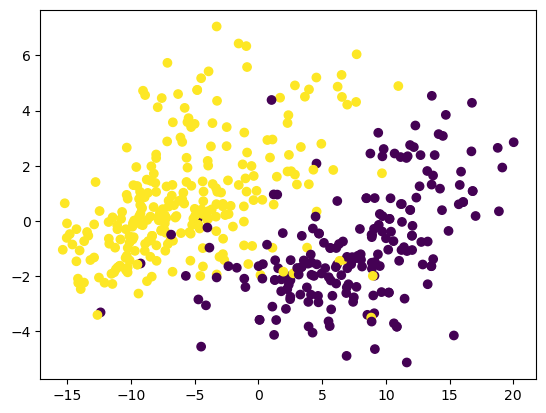

In [5]:
from sklearn.decomposition import PCA
X_2 = PCA(2).fit_transform(X_test)
y_2 = y_test
plt.scatter(X_2[:,0],X_2[:,1],c=y_2)

In [6]:
# 4.输出预测数据
# 输出模型预测值,X_t和y_t为实际值，y_p为模型预测值
header_list = list(pd.read_excel("36RNA的原始数据.xlsx")[:0])
header = [header_list[i] for i in random_index]
for label,X_t,y_t in [['train',X_train,y_train],['test',X_test,y_test]]:
    data_file = open('svm_b0_pred_{}.txt'.format(label),'w')
    y_p = model.predict(X_t)
    data_file.writelines('{:12}{:12}'.format('true_0','pred_0'))
    for head in header:
        data_file.writelines('{:15}'.format(head))
    data_file.writelines('\n')
    for i in range(len(y_p)):    
        data_file.writelines('{:<12}{:<12.5f}'.format(y_t[i],y_p[i]))
        for j in range(len(X_t[i])):
            data_file.writelines('{:<15.8f}'.format(X_t[i][j]))
        data_file.writelines('\n')
    data_file.close()

In [7]:
print(model.coef_)
print(model.intercept_)

[[-1.53143258 -0.01922888 -0.00507713  0.046523   -0.47140835 -0.0379293
   1.02961893 -0.20449949 -0.39611279 -0.06543756 -0.11505294  0.25688412
  -0.57710847  0.81796442  0.18832355  0.4785436  -0.17272377 -1.15247954
   0.43454976 -0.01202292 -0.4219421   0.62471337  1.16640785 -0.13486293
   0.18612082  0.39479219  0.10780651 -0.65321512  0.93493391 -0.07393952
   0.4960321  -1.01292714 -0.01677418 -0.3873298  -0.10410141 -0.09386249]]
0.0


In [8]:
# #保存模型
joblib.dump(model, "svm_model.h5")

['svm_model.h5']